# DxForge — 02 · Model Training, Validation & Optimisation

**Rubric coverage:** Model Development using Syllabus Techniques (18) · Model Evaluation, Validation & Optimisation (15) · Feature Selection & Dimensionality Reduction (8)

| Task | Type | Models compared | Validation |
|---|---|---|---|
| Intent → UDS service | 13-class text classification | Multinomial NB, Logistic Regression, Linear SVM, KNN, Decision Tree, Random Forest, MLP | 5-fold **StratifiedGroupKFold** by paraphrase template + external hand-written challenge set |
| Request outcome | tabular binary + 6-class NRC | Decision Tree (d=4, d=8), Random Forest, Gradient Boosting | 5-fold stratified CV + **unseen ECU profile** |
| ECU defect detection | unsupervised anomaly detection | Isolation Forest, One-Class SVM (+ engine oracle) | golden-run training, labelled faulty run for scoring |

The ML layer only **proposes**. Final protocol bytes always come from the deterministic engine.

In [1]:
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, f1_score, accuracy_score,
                             roc_curve, precision_recall_curve, roc_auc_score, average_precision_score)
from sklearn.model_selection import cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

from dxforge.kb import load_kb
from dxforge.ml import SEED
from dxforge.ml.dataset import (generate_intents, clean_intents, generate_outcomes, generate_traces,
                                HELDOUT_PROFILE, SESSION_RANK)
from dxforge.ml.text import normalize
from dxforge.ml import intent_model as im, outcome_model as om, defect_model as dm
from dxforge.ml.features import domain_tabular, raw_tabular

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})
kb = load_kb()
MODELS = ROOT / "models"
metrics = json.loads((MODELS / "metrics.json").read_text())
print("seed", SEED, "| metrics.json trained in", "quick" if metrics.get("quick") else "full", "mode")

seed 42 | metrics.json trained in full mode


## Part A — Intent classifier

In [2]:
intent_df, _ = clean_intents(generate_intents(kb, scale=1.0, seed=SEED))
challenge = pd.read_csv(ROOT / "data" / "ml" / "challenge_intents.csv")
challenge["text_clean"] = challenge["text"].map(normalize)
print(f"training pool: {len(intent_df):,} rows, {intent_df.template_id.nunique()} paraphrase groups")
print(f"external challenge set: {len(challenge)} hand-written rows (never used for training or tuning)")

training pool: 4,185 rows, 135 paraphrase groups
external challenge set: 67 hand-written rows (never used for training or tuning)


### A1. Candidate model comparison — 5-fold StratifiedGroupKFold
Every fold's test templates are unseen during training, so these scores measure generalisation to new phrasings, not memorisation.

In [3]:
t0 = time.time()
comp = im.compare_models(intent_df, n_splits=5)
print(f"({time.time() - t0:.0f}s)")
comp.style.format({c: "{:.3f}" for c in comp.columns if c != "model"}).background_gradient(
    subset=["cv_f1_macro_mean"], cmap="Greens")

(76s)


,model,cv_accuracy_mean,cv_accuracy_std,cv_f1_macro_mean,cv_f1_macro_std,fit_time_s
0,Multinomial NB,0.819,0.032,0.783,0.031,0.771
1,Logistic Regression,0.822,0.056,0.761,0.056,1.447
2,MLP (1x128),0.810,0.056,0.752,0.062,39.894
3,Linear SVM,0.814,0.065,0.747,0.073,1.059
4,KNN (cosine),0.717,0.046,0.670,0.052,0.571
5,Random Forest,0.692,0.052,0.624,0.058,12.412
6,Decision Tree,0.573,0.076,0.482,0.082,2.128


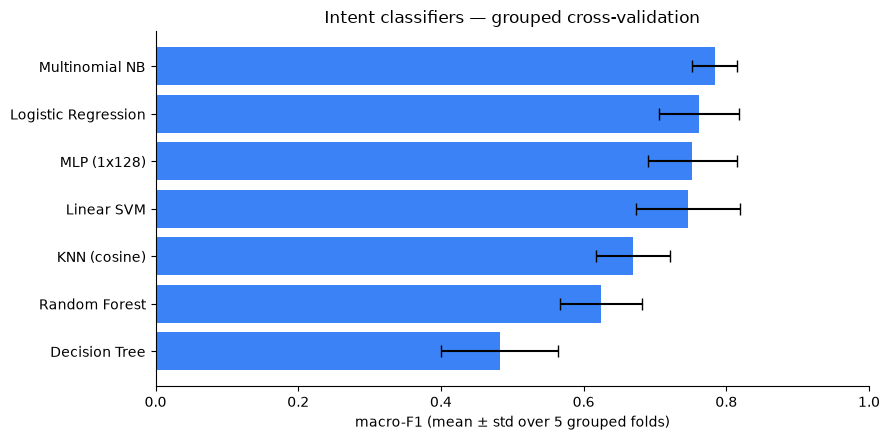

In [4]:
c = comp.sort_values("cv_f1_macro_mean")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(c["model"], c["cv_f1_macro_mean"], xerr=c["cv_f1_macro_std"], color="#3b82f6", capsize=4)
ax.set_xlabel("macro-F1 (mean ± std over 5 grouped folds)"); ax.set_xlim(0, 1)
ax.set_title("Intent classifiers — grouped cross-validation")
plt.tight_layout(); plt.show()

**Reading the table.** Linear models and Naive Bayes do well on sparse, high-dimensional TF-IDF, where classes are close to linearly separable.
A single unpruned decision tree splits on individual n-grams and overfits paraphrase-specific tokens. That is why it is the weakest model, and why bagging (Random Forest) recovers much of the gap.

### A2. Hyper-parameter optimisation — GridSearchCV (feature representation × C)
Logistic Regression is tuned rather than the top-ranked model when they are within noise, because the confidence gate needs **probabilities** (`predict_proba`), which LinearSVC lacks.

(27s)  best: word(1, 2)+char(2, 5)  C=30.0  CV macro-F1=0.762


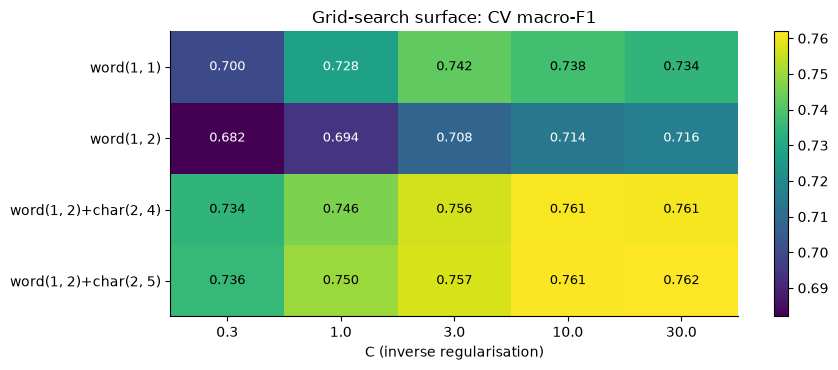

,features,C,cv_f1_macro,cv_f1_std,train_f1_macro
0,"word(1, 2)+char(2, 5)",30.0,0.761942,0.055644,1.000000
1,"word(1, 2)+char(2, 5)",10.0,0.761470,0.056003,1.000000
2,"word(1, 2)+char(2, 4)",10.0,0.761073,0.051926,1.000000
3,"word(1, 2)+char(2, 4)",30.0,0.760962,0.056184,1.000000
4,"word(1, 2)+char(2, 5)",3.0,0.756989,0.051948,0.999933
5,"word(1, 2)+char(2, 4)",3.0,0.756496,0.052829,0.999933
6,"word(1, 2)+char(2, 5)",1.0,0.749899,0.055686,0.999586
7,"word(1, 2)+char(2, 4)",1.0,0.746181,0.054534,0.999585


In [5]:
t0 = time.time()
gs = im.tune(intent_df, n_splits=5)
gt = im.grid_table(gs)
print(f"({time.time() - t0:.0f}s)  best: {gt.iloc[0]['features']}  C={gt.iloc[0]['C']}  CV macro-F1={gt.iloc[0]['cv_f1_macro']:.3f}")
surface = gt.pivot_table(index="features", columns="C", values="cv_f1_macro")
fig, ax = plt.subplots(figsize=(9, 3.8))
im_ = ax.imshow(surface.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(surface.shape[1])); ax.set_xticklabels(surface.columns)
ax.set_yticks(range(surface.shape[0])); ax.set_yticklabels(surface.index)
for i in range(surface.shape[0]):
    for j in range(surface.shape[1]):
        v = surface.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                color="black" if v > np.nanmean(surface.values) else "white")
ax.set_xlabel("C (inverse regularisation)"); ax.set_title("Grid-search surface: CV macro-F1")
fig.colorbar(im_); plt.tight_layout(); plt.show()
gt.head(8)

### A3. Over/under-fitting — learning curve and validation curve

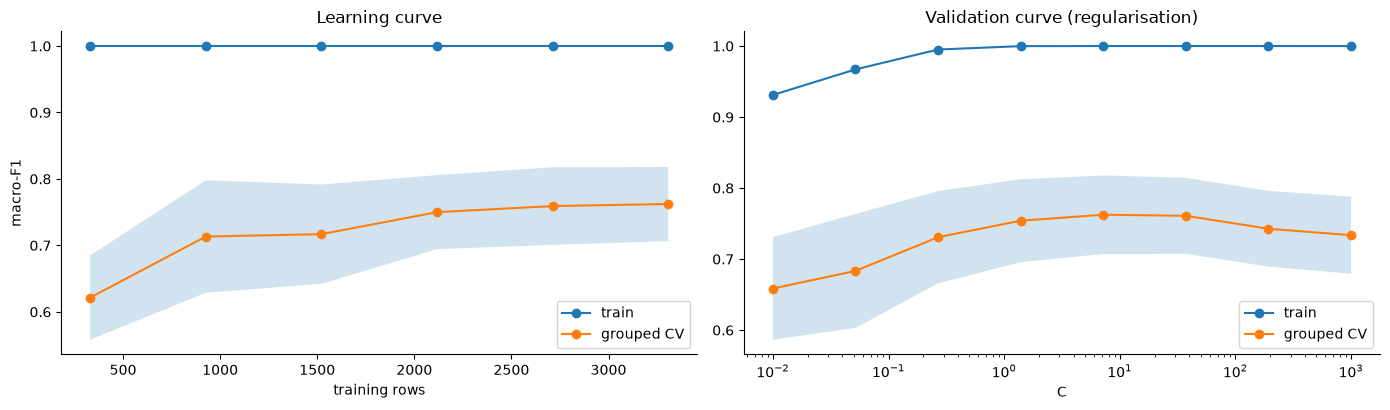

train-CV gap at full size: 0.238. A large gap is the variance that unseen phrasings cause;
the still-rising CV curve says more paraphrase diversity (not a bigger model) is the lever.


In [6]:
best = gs.best_estimator_
cv = im.curves(best, intent_df, n_splits=5)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.2))
a1.plot(cv["sizes"], cv["lc_train"], "o-", label="train")
a1.plot(cv["sizes"], cv["lc_test"], "o-", label="grouped CV")
a1.fill_between(cv["sizes"], np.array(cv["lc_test"]) - cv["lc_test_std"], np.array(cv["lc_test"]) + cv["lc_test_std"], alpha=0.2)
a1.set_xlabel("training rows"); a1.set_ylabel("macro-F1"); a1.set_title("Learning curve"); a1.legend()
a2.semilogx(cv["c_range"], cv["vc_train"], "o-", label="train")
a2.semilogx(cv["c_range"], cv["vc_test"], "o-", label="grouped CV")
a2.fill_between(cv["c_range"], np.array(cv["vc_test"]) - cv["vc_test_std"], np.array(cv["vc_test"]) + cv["vc_test_std"], alpha=0.2)
a2.set_xlabel("C"); a2.set_title("Validation curve (regularisation)"); a2.legend()
plt.tight_layout(); plt.show()
gap = cv["lc_train"][-1] - cv["lc_test"][-1]
print(f"train-CV gap at full size: {gap:.3f}. A large gap is the variance that unseen phrasings cause;")
print("the still-rising CV curve says more paraphrase diversity (not a bigger model) is the lever.")

### A4. Confusion matrix — all 13 classes (out-of-fold, grouped)
Every prediction comes from a model that never saw that row's template.

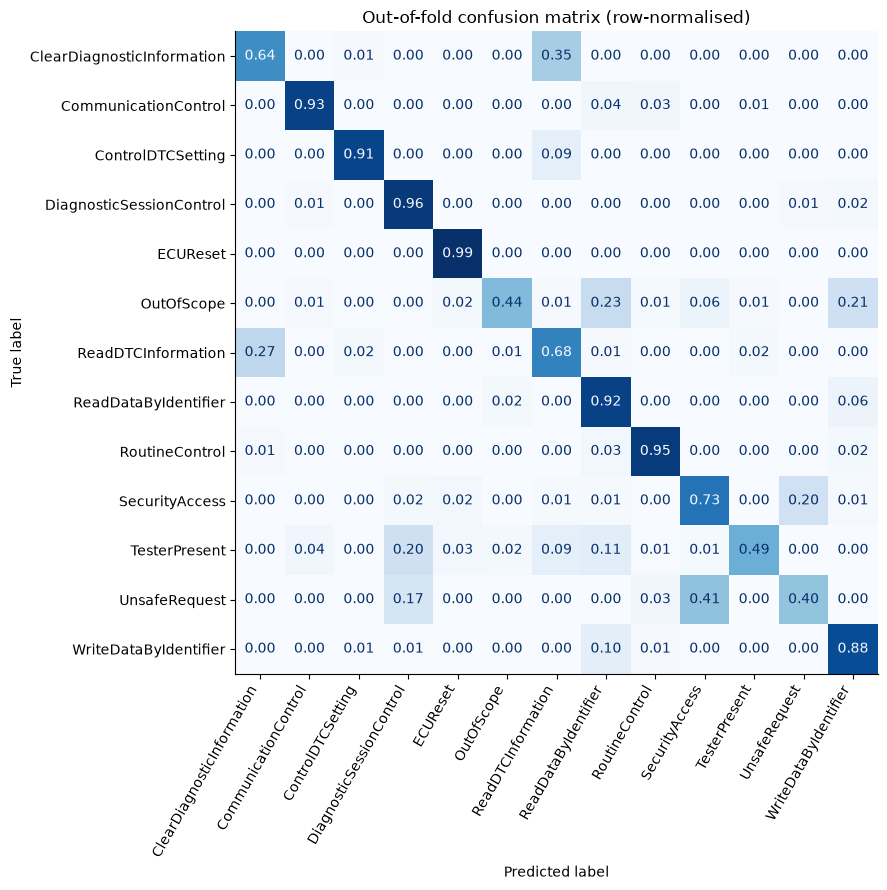

                            precision    recall  f1-score   support

ClearDiagnosticInformation      0.613     0.635     0.624       244
      CommunicationControl      0.925     0.925     0.925       161
         ControlDTCSetting      0.925     0.912     0.918       148
  DiagnosticSessionControl      0.876     0.956     0.914       435
                  ECUReset      0.942     0.992     0.967       263
                OutOfScope      0.836     0.440     0.576       232
        ReadDTCInformation      0.662     0.675     0.669       345
      ReadDataByIdentifier      0.843     0.924     0.882       878
            RoutineControl      0.951     0.947     0.949       414
            SecurityAccess      0.770     0.733     0.751       251
             TesterPresent      0.891     0.494     0.636       166
             UnsafeRequest      0.413     0.396     0.404        96
     WriteDataByIdentifier      0.807     0.880     0.842       552

                  accuracy                    

In [7]:
oof = cross_val_predict(clone(best), intent_df["text_clean"], intent_df["label"],
                        groups=intent_df["template_id"], cv=im.cv_splitter(5), method="predict_proba", n_jobs=-1)
classes = np.array(sorted(intent_df["label"].unique()))
oof_pred = classes[oof.argmax(1)]
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(intent_df["label"], oof_pred, labels=classes, normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
plt.xticks(rotation=60, ha="right"); ax.set_title("Out-of-fold confusion matrix (row-normalised)")
plt.tight_layout(); plt.show()
print(classification_report(intent_df["label"], oof_pred, digits=3, zero_division=0))

### A5. Selective classification — the confidence gate
The threshold is picked on **out-of-fold** probabilities (not on the test set): the lowest confidence at which answered predictions reach the target accuracy (`CONFIDENCE_TARGET` = 90% on unseen phrasings). Below it the ML abstains and the request goes to the keyword parser or is refused.

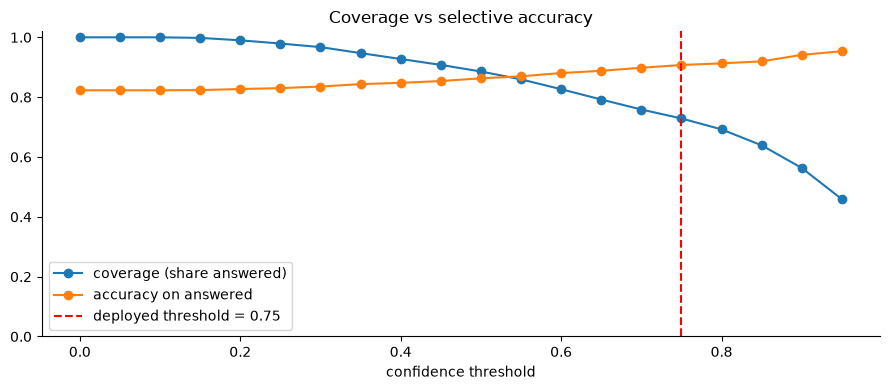

,threshold,coverage,selective_accuracy
0,0.00,1.000000,0.822939
12,0.60,0.826523,0.880601
15,0.75,0.728793,0.907541
16,0.80,0.692234,0.913013


In [8]:
curve = im.coverage_curve(oof, classes, intent_df["label"])
thr = joblib.load(MODELS / "intent_clf.joblib")["threshold"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve["threshold"], curve["coverage"], "o-", label="coverage (share answered)")
ax.plot(curve["threshold"], curve["selective_accuracy"], "o-", label="accuracy on answered")
ax.axvline(thr, color="red", ls="--", label=f"deployed threshold = {thr:.2f}")
ax.set_xlabel("confidence threshold"); ax.set_ylim(0, 1.02); ax.legend(); ax.set_title("Coverage vs selective accuracy")
plt.tight_layout(); plt.show()
curve[curve.threshold.isin([0.0, thr, 0.6, 0.8])]

### A6. Feature selection (χ²) and dimensionality reduction (TruncatedSVD)

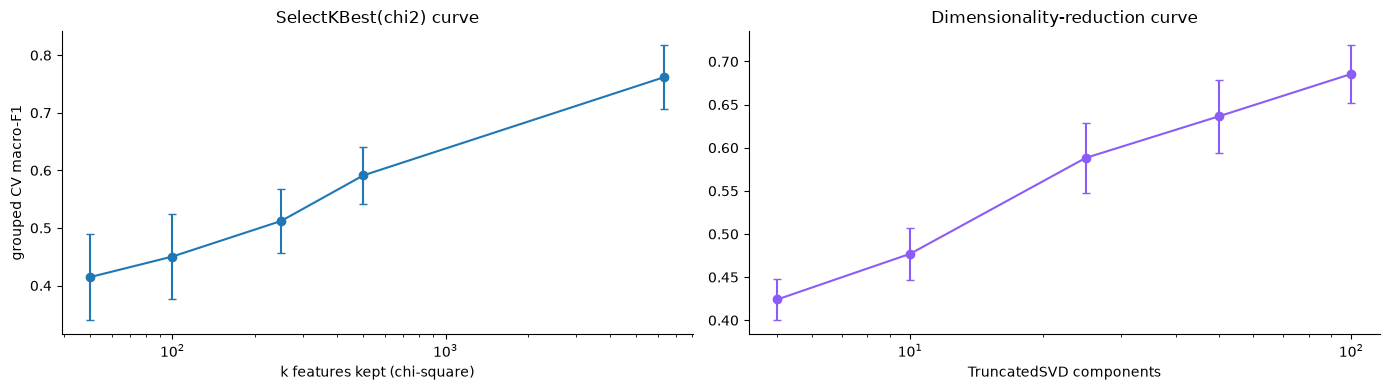

,method,dims,cv_f1_macro,cv_f1_std
0,chi2 k-best,50,0.414796,0.075109
1,chi2 k-best,100,0.450417,0.074596
2,chi2 k-best,250,0.512164,0.055653
3,chi2 k-best,500,0.591328,0.050030
4,chi2 k-best,6326,0.761942,0.055644
0,TruncatedSVD,5,0.424157,0.024197
1,TruncatedSVD,10,0.477041,0.029821
2,TruncatedSVD,25,0.588231,0.040858
3,TruncatedSVD,50,0.636317,0.042545
4,TruncatedSVD,100,0.685555,0.033461


In [9]:
fs = pd.DataFrame(metrics["intent"]["feature_selection_curve"])
sv = pd.DataFrame(metrics["intent"]["svd_curve"])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4))
a1.errorbar(fs["k"], fs["cv_f1_macro"], yerr=fs["cv_f1_std"], fmt="o-", capsize=3)
a1.set_xscale("log"); a1.set_xlabel("k features kept (chi-square)"); a1.set_ylabel("grouped CV macro-F1")
a1.set_title("SelectKBest(chi2) curve")
a2.errorbar(sv["components"], sv["cv_f1_macro"], yerr=sv["cv_f1_std"], fmt="o-", capsize=3, color="#8b5cf6")
a2.set_xscale("log"); a2.set_xlabel("TruncatedSVD components"); a2.set_title("Dimensionality-reduction curve")
plt.tight_layout(); plt.show()
pd.concat([fs.assign(method="chi2 k-best").rename(columns={"k": "dims"}),
           sv.assign(method="TruncatedSVD").rename(columns={"components": "dims"})])[["method", "dims", "cv_f1_macro", "cv_f1_std"]]

### A7. External test — hand-written challenge set vs baselines
Phrasings, typos and adversarial requests written separately from the templates. Baselines: majority class and the original keyword parser.

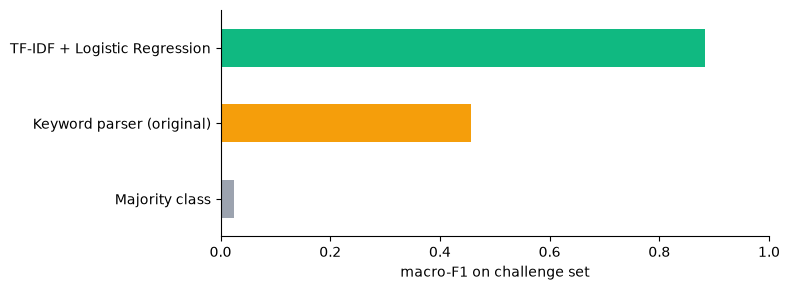

,accuracy,f1_macro
Majority class,0.194,0.025
Keyword parser (original),0.463,0.456
TF-IDF + Logistic Regression,0.896,0.883


In [10]:
base = metrics["intent"]["challenge_baselines"]
tbl = pd.DataFrame(base).T.rename(index={"majority_class": "Majority class", "keyword_parser": "Keyword parser (original)",
                                         "ml_logreg": "TF-IDF + Logistic Regression"})
ax = tbl["f1_macro"].plot(kind="barh", figsize=(8, 3), color=["#9ca3af", "#f59e0b", "#10b981"])
ax.set_xlabel("macro-F1 on challenge set"); ax.set_xlim(0, 1); plt.tight_layout(); plt.show()
tbl.round(3)

In [11]:
errs = pd.read_csv(MODELS / "intent_errors.csv")
print(f"{len(errs)} challenge-set errors — error analysis:")
errs

7 challenge-set errors — error analysis:


,text,label,predicted
0,how hot is it inside the cabin,ReadDataByIdentifier,OutOfScope
1,reset faults after repair,ClearDiagnosticInformation,ECUReset
2,clr dtc,ClearDiagnosticInformation,ControlDTCSetting
3,keep ecu awake in extended session,TesterPresent,DiagnosticSessionControl
4,what's the recommended tyre pressure for highways,OutOfScope,ReadDTCInformation
5,write a poem about cars,OutOfScope,WriteDataByIdentifier
6,reprogram the ecu while driving on the highway,UnsafeRequest,ECUReset


## Part B — Tabular outcome model
Predict whether the ECU accepts a request (positive/negative) from request + context. Train on 3 ECU profiles, test on the unseen `DCU-DEMO`.

In [12]:
outcome_df = generate_outcomes(n_per_profile=2000, seed=SEED)
train_out = outcome_df[outcome_df.ecu_id != HELDOUT_PROFILE]
test_out = outcome_df[outcome_df.ecu_id == HELDOUT_PROFILE]
print(f"train {len(train_out):,} rows (3 ECUs)  |  held-out ECU {HELDOUT_PROFILE}: {len(test_out):,} rows")
oc = om.compare_models(train_out, n_splits=5)
oc.round(4)

train 6,000 rows (3 ECUs)  |  held-out ECU DCU-DEMO: 2,000 rows


,model,cv_accuracy_mean,cv_accuracy_std,cv_f1_macro_mean,cv_f1_macro_std,fit_time_s
0,Gradient Boosting,1.0000,0.0000,1.0000,0.0000,1.3500
1,Decision Tree (depth=8),0.9998,0.0003,0.9998,0.0003,0.0174
2,Random Forest,0.9998,0.0003,0.9998,0.0003,1.3801
3,Decision Tree (depth=4),0.9607,0.0041,0.9604,0.0042,0.0112


### B1. Feature engineering ablation — raw IDs vs KB-derived domain features
Two questions: does it help in-distribution (CV), and does it help on an **ECU the model has never seen**?

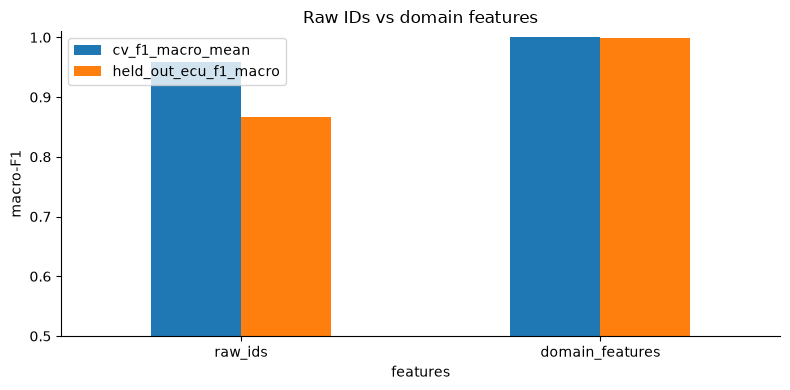

,features,n_features,cv_accuracy_mean,cv_f1_macro_mean,held_out_ecu_f1_macro
0,raw_ids,6,0.9587,0.9585,0.8665
1,domain_features,25,0.9998,0.9998,0.9985


In [13]:
fcmp = om.feature_comparison(train_out, n_splits=5)
y_tr = (train_out["label"] == "POSITIVE").astype(int); y_te = (test_out["label"] == "POSITIVE").astype(int)
held = {}
for name, fn in [("raw_ids", raw_tabular), ("domain_features", domain_tabular)]:
    rf = RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1)
    rf.fit(fn(train_out), y_tr)
    held[name] = f1_score(y_te, rf.predict(fn(test_out)), average="macro")
fcmp["held_out_ecu_f1_macro"] = fcmp["features"].map(held)
ax = fcmp.set_index("features")[["cv_f1_macro_mean", "held_out_ecu_f1_macro"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylim(0.5, 1.01); ax.set_ylabel("macro-F1"); ax.set_title("Raw IDs vs domain features")
plt.tight_layout(); plt.show()
fcmp.round(4)

### B2. Feature importance (impurity and permutation on the unseen ECU)

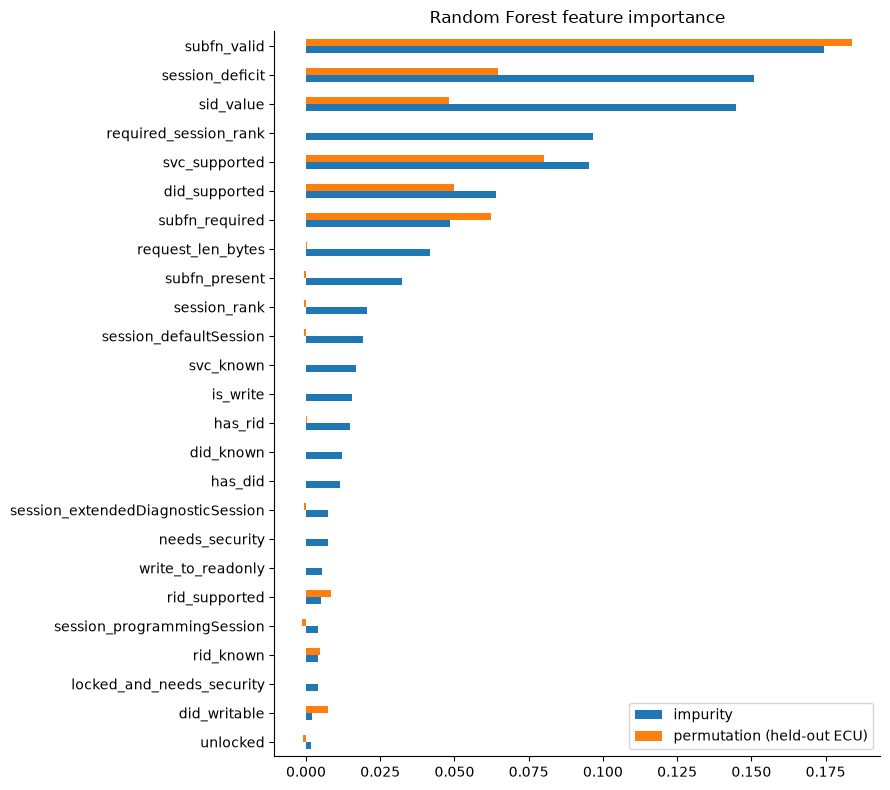

held-out ECU accuracy: 0.9985  macro-F1: 0.9985


In [14]:
rf_final, cols = om.fit_final(train_out)
X_te = domain_tabular(test_out)[cols]
imp = pd.DataFrame({"impurity": rf_final.feature_importances_}, index=cols)
perm = permutation_importance(rf_final, X_te, y_te, n_repeats=10, random_state=SEED, n_jobs=-1)
imp["permutation (held-out ECU)"] = perm.importances_mean
imp = imp.sort_values("impurity")
imp.plot(kind="barh", figsize=(9, 8)); plt.title("Random Forest feature importance")
plt.tight_layout(); plt.show()
print("held-out ECU accuracy:", round(accuracy_score(y_te, rf_final.predict(X_te)), 4),
      " macro-F1:", round(f1_score(y_te, rf_final.predict(X_te), average="macro"), 4))

### B3. Interpretable model — depth-4 Decision Tree recovers the engine's rules
The shallow tree is an audit tool. If its learned splits match the engine's documented rule order (service support → sub-function → DID/RID → session → security), the data and the engine agree.

In [15]:
print(om.tree_rules(train_out, max_depth=4))

|--- session_deficit <= 0.50
|   |--- subfn_valid <= 0.50
|   |   |--- sid_value <= 34.50
|   |   |   |--- subfn_required <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- subfn_required >  0.50
|   |   |   |   |--- class: 0
|   |   |--- sid_value >  34.50
|   |   |   |--- did_writable <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- did_writable >  0.50
|   |   |   |   |--- class: 0
|   |--- subfn_valid >  0.50
|   |   |--- svc_supported <= 0.50
|   |   |   |--- class: 0
|   |   |--- svc_supported >  0.50
|   |   |   |--- locked_and_needs_security <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- locked_and_needs_security >  0.50
|   |   |   |   |--- class: 0
|--- session_deficit >  0.50
|   |--- class: 0



In [16]:
print("Multi-class NRC prediction on negative rows (5-fold stratified CV):")
om.nrc_model(train_out, n_splits=5).round(4)

Multi-class NRC prediction on negative rows (5-fold stratified CV):


,task,n_classes,cv_accuracy_mean,cv_f1_macro_mean
0,NRC prediction (negative rows),6,1.0,1.0


## Part C — ECU defect detection (unsupervised)
Detectors are trained on a golden run only (no labels), then scored on a faulty run with 15% injected defects.

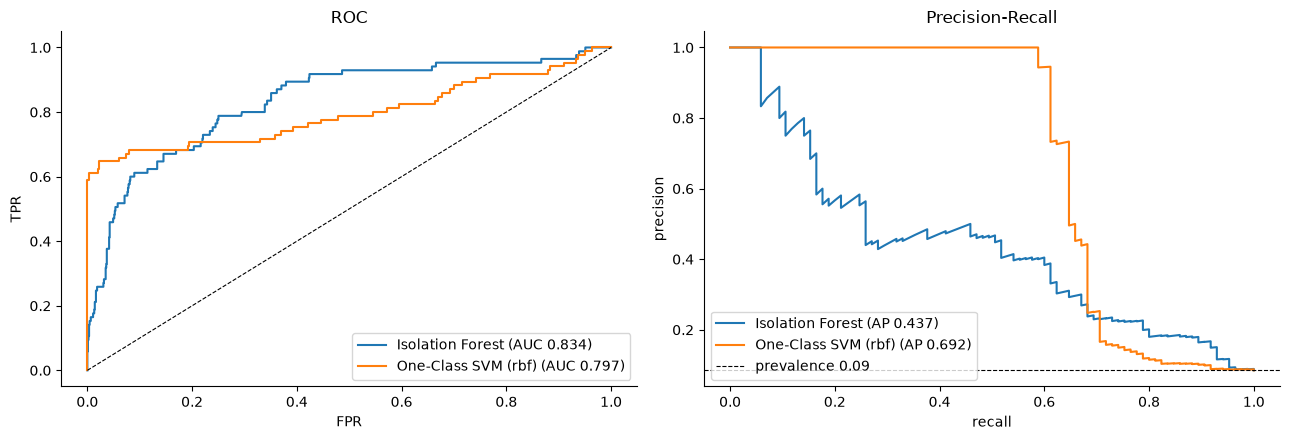

,model,roc_auc,avg_precision,precision,recall
0,Isolation Forest,0.834,0.437,0.386,0.600
1,One-Class SVM (rbf),0.797,0.692,0.395,0.682


In [17]:
X_train, X_test, y_test, dtypes, feat = dm.build_datasets(n_train=3000, n_test=1000, defect_rate=0.15)
scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)
iforest = IsolationForest(n_estimators=200, contamination=0.1, random_state=SEED, n_jobs=-1).fit(Xtr)
ocsvm = OneClassSVM(kernel="rbf", nu=0.1).fit(Xtr)
scores_ = {"Isolation Forest": -iforest.score_samples(Xte), "One-Class SVM (rbf)": -ocsvm.decision_function(Xte)}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, s in scores_.items():
    fpr, tpr, _ = roc_curve(y_test, s); p, r, _ = precision_recall_curve(y_test, s)
    a1.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, s):.3f})")
    a2.plot(r, p, label=f"{name} (AP {average_precision_score(y_test, s):.3f})")
a1.plot([0, 1], [0, 1], "k--", lw=0.8); a1.set_xlabel("FPR"); a1.set_ylabel("TPR"); a1.set_title("ROC"); a1.legend()
a2.axhline(y_test.mean(), color="k", ls="--", lw=0.8, label=f"prevalence {y_test.mean():.2f}")
a2.set_xlabel("recall"); a2.set_ylabel("precision"); a2.set_title("Precision-Recall"); a2.legend()
plt.tight_layout(); plt.show()
pd.DataFrame(metrics["defect"]).round(3)

### C1. ML + rules: what each detector catches
The **engine oracle** compares the observed response with the engine's expected outcome/NRC. It catches every *semantic* defect but cannot see timing or truncation.
The anomaly detector covers the reverse. The union is the deployed design.

In [18]:
test_raw = generate_traces(n=1000, defect_rate=0.15, seed=SEED + 1)
obs_neg = test_raw["response_sid"] == 0x7F
exp_neg = test_raw["expected_outcome"] == "negative"
oracle = (test_raw["resp_len"] > 0) & ((obs_neg != exp_neg) | (obs_neg & (test_raw["nrc"] != test_raw["expected_nrc"])))
iforest_flag = pd.Series(iforest.predict(Xte) == -1, index=test_raw.index)
hybrid = oracle | iforest_flag
truth = test_raw["defect"] != "none"
rows = []
for name, flag in [("Isolation Forest", iforest_flag), ("Engine oracle", oracle), ("Hybrid (union)", hybrid)]:
    rec = test_raw.assign(f=flag).groupby("defect")["f"].mean()
    rows.append({"detector": name, "precision": (flag & truth).sum() / max(flag.sum(), 1),
                 "recall": (flag & truth).sum() / truth.sum(), **{f"recall:{k}": v for k, v in rec.items() if k != "none"},
                 "false-alarm rate": flag[~truth].mean()})
pd.DataFrame(rows).set_index("detector").round(3).T

detector,Isolation Forest,Engine oracle,Hybrid (union)
precision,0.386,1.000,0.481
recall,0.600,0.341,0.882
recall:latency_violation,0.852,0.000,0.852
recall:timeout,1.000,0.000,1.000
recall:truncated_response,0.000,0.000,0.000
recall:unexpected_negative,0.308,1.000,1.000
recall:unexpected_positive,0.111,1.000,1.000
recall:wrong_nrc,0.000,1.000,1.000
false-alarm rate,0.089,0.000,0.089


## Summary
* **Intent:** linear text models and Naive Bayes beat trees on sparse TF-IDF under template-grouped CV. The tuned Logistic Regression beats the keyword parser and the majority baseline on the external challenge set, and abstains when unsure.
* **Outcome:** KB-derived domain features beat raw IDs, most of all on an unseen ECU profile. A depth-4 tree exposes the learned rules for audit.
* **Defects:** Isolation Forest catches timing/length anomalies without labels. The deterministic oracle catches semantic NRC defects. Their union is the deployed detector.
* **Limits:** all data is synthetic (see the model card). These numbers show the method works; they are not field accuracy.